<h1>Importing libraries</h1>

In [128]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
from pathlib import Path

<h1>Import player results</h1>

In [171]:
player_results = pd.read_csv(
    f"{Path.cwd().parent}/data/processed/player_results.csv"
)

#player_results = player_results[['m', 's', 'male_name', 'chaser_name']]
player_results.loc[player_results['male_name'] > 0.5, 'male_name'] = 1
player_results.loc[player_results['male_name'] <= 0.5, 'male_name'] = 0

player_results.head()

,episode_date,player_number,player_name,middle_offer_nominal,chaser_name,low_offer_nominal,high_offer_nominal,s,m,fc_correct_answers,...,total_bank_nominal,month,cpi,low_offer_real,middle_offer_real,high_offer_real,money_banked_real,total_bank_real,fc_team_win,male_name
0,2010-05-24,1,Matthew,9000,Shaun Wallace,4000.0,20000,0,4,6,...,0,2010-05,89.4,4474.27,10067.11,22371.36,10067.11,0.00,0,1.0
1,2010-05-24,2,Angela,7000,Shaun Wallace,2000.0,20000,1,3,5,...,9000,2010-05,89.4,2237.14,7829.98,22371.36,2237.14,10067.11,0,0.0
2,2010-05-24,3,Les,14000,Shaun Wallace,1000.0,29000,0,-3,0,...,11000,2010-05,89.4,1118.57,15659.96,32438.48,0.00,12304.25,0,1.0
3,2010-05-24,4,Rebecca,5000,Shaun Wallace,100.0,22000,0,1,5,...,11000,2010-05,89.4,111.86,5592.84,24608.50,5592.84,12304.25,0,0.0
4,2010-05-25,1,Roger,9000,Mark Labbett,4000.0,14000,0,2,5,...,0,2010-05,89.4,4474.27,10067.11,15659.96,10067.11,0.00,0,1.0


<h2>By gender</h2>

In [176]:
player_results.groupby('male_name')['won_hth'].mean()

male_name
0.0    0.584057
1.0    0.625878
Name: won_hth, dtype: float64

In [183]:
player_results.groupby('male_name')['m'].mean()

male_name
0.0    0.174509
1.0    0.374925
Name: m, dtype: float64

Players with more masculine names tend to perform better in head-to-heads

<h2>By chaser</h2>

In [180]:
player_results.groupby('chaser_name')['won_hth'].mean().sort_values()

chaser_name
Shaun Wallace    0.585366
Anne Hegerty     0.591451
Mark Labbett     0.612235
Darragh Ennis    0.613043
Paul Sinha       0.618345
Jenny Ryan       0.625332
Name: won_hth, dtype: float64

In [182]:
player_results.groupby('chaser_name')['m'].mean().sort_values()

chaser_name
Shaun Wallace    0.189933
Anne Hegerty     0.212724
Mark Labbett     0.287617
Darragh Ennis    0.326087
Paul Sinha       0.352135
Jenny Ryan       0.353410
Name: m, dtype: float64

There's a clear hierachy showing here who's the best performing chaser in head-to-heads

<h1>Import Monte-Carlo simulated head-to-head results</h1>

In [129]:
mc_head_to_head_results = pd.read_csv(
    f"{Path.cwd().parent}/data/processed/mc_head_to_head_results.csv", 
    dtype={
        'theta_p': np.float64,
        'theta_c': np.float64,
        's': 'Int64',
        'i': 'Int64',
        'P': 'Int64',
        'C': 'Int64',
        'm': 'Int64',
        't': 'Int64',
        'player_win': 'Int64'}
)

mc_head_to_head_results.head()

,theta_p,theta_c,s,i,P,C,m,t,player_win
0,0.3333,0.3333,-1,5,2,2,-6,2,0
1,0.3333,0.3333,-1,6,4,4,-4,7,0
2,0.3333,0.3333,-1,8,3,3,-5,3,0
3,0.3333,0.3333,-1,9,8,1,6,8,1
4,0.3333,0.3333,-1,10,3,3,-5,3,0


<h1>Calculating posterior probabilities</h1>
We want to calculate two different distributions:
$$P(\theta_p = \theta_{p,i} | g=g_i) = \sum_{m, s} P(\theta_p = \theta_{p,i}|m=m_i, s=s_i)P(m=m_i, s=s_i| g=g_i)$$ and 
$$P(\theta_c = \theta_{c,i} | c = c_i) = \sum_{m, s} P(\theta_c = \theta_{c,i}|m=m_i, s=s_i)P(m=m_i, s=s_i | c = c_i)$$
<h2>$\theta_p$ and $f$</h2>
$$P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}|m=m_i, s=s_i)$$
<p>Given that a player $i$ wins (or loses) their head-to-head with margin $m$ after choosing a particular offer $s$, what's the probability that their accuracy is $\theta_p$ and the chaser's is $\theta_c = \theta_p + f$? We can use the  Monte-Carlo simulated head-to-head results to find this conditional probability.</p> 

In [130]:
# Count of each combination of theta_p, f, margin and s
joint = mc_head_to_head_results.groupby(["theta_p", "theta_c", "m", "s"]).size()

# Count of each combination of margin and s
evidence = mc_head_to_head_results.groupby(["m", "s"]).size()

# Posterior P(theta_p, f, margin, s | margin, s) = #(theta_p, f, margin, s) / #(margin, s)
posterior = (joint / evidence).rename("posterior_theta_p_theta_c").reset_index()
posterior = posterior[["m", "s", "theta_p", "theta_c", "posterior_theta_p_theta_c"]]
posterior = posterior.sort_values(by=["m", "s","theta_p", "theta_c"])
posterior.head()

,m,s,theta_p,theta_c,posterior_theta_p_theta_c
0,-6,-1,0.3333,0.3333,0.000372
1,-6,-1,0.3333,0.3433,0.000386
2,-6,-1,0.3333,0.3532,0.000438
3,-6,-1,0.3333,0.3632,0.000424
4,-6,-1,0.3333,0.3731,0.000461


<h1>Margin and offer choice</h1>

<h3>Find proportion of individual margins and choices by gender</h3>

Now we'll work out the next part of the equation:
$$P(m=m_i, s=s_i | g=g_i)$$

In [132]:
joint_gender = player_results.groupby(["m", "s", "male_name"]).size()

# Count of each gender
evidence_gender = player_results.groupby(["male_name"]).size()

# Posterior P(theta_p, f, margin, s | margin, s) = #(theta_p, f, margin, s) / #(margin, s)
posterior_gender = (joint_gender / evidence_gender).rename("posterior_m_s").reset_index()
posterior_gender = posterior_gender[["m", "s", "male_name", "posterior_m_s"]]
posterior_gender = posterior_gender.sort_values(by=["m", "s", "male_name", "posterior_m_s"])
posterior_gender.head()

,m,s,male_name,posterior_m_s
0,-6,-1,0.0,0.008680
1,-6,-1,1.0,0.014443
2,-5,-1,0.0,0.012791
3,-5,-1,1.0,0.017252
4,-5,0,0.0,0.030608


<h3>Find proportion of individual margins and choices by chaser</h3>

Now we'll work out the next part of the equation:
$$P(m=m_i, s=s_i | c=c_i)$$

In [133]:
joint_chaser = player_results.groupby(["m", "s", "chaser_name"]).size()

# Count of each chaser
evidence_chaser = player_results.groupby(["chaser_name"]).size()

# Posterior P(theta_p, f, margin, s | margin, s) = #(theta_p, f, margin, s) / #(margin, s)
posterior_chaser = (joint_chaser / evidence_chaser).rename("posterior_m_s").reset_index()
posterior_chaser = posterior_chaser[["m", "s", "chaser_name", "posterior_m_s"]]
posterior_chaser = posterior_chaser.sort_values(by=["m", "s", "chaser_name", "posterior_m_s"])
posterior_chaser.head()

,m,s,chaser_name,posterior_m_s
0,-6,-1,Anne Hegerty,0.012425
1,-6,-1,Darragh Ennis,0.010870
2,-6,-1,Jenny Ryan,0.012400
3,-6,-1,Mark Labbett,0.009867
4,-6,-1,Paul Sinha,0.011597


<h3>Combining the two probabilities</h3>

Now we can work out our distribution: $$P(\theta_p = \theta_{p,i} | g=g_i) = \sum_{m, s} P(\theta_p = \theta_{p,i}|m=m_i, s=s_i)P(m=m_i, s=s_i | g=g_i)$$

In [139]:
p_merged_gender = posterior_gender.merge(posterior, on=["m", "s"], how="left")
p_merged_gender['p_theta_p'] = p_merged_gender['posterior_m_s'] * p_merged_gender['posterior_theta_p_theta_c']
p_theta_p = p_merged_gender.groupby(["theta_p",'male_name'])["p_theta_p"].sum().reset_index()

p_theta_p

,theta_p,male_name,p_theta_p
0,0.3333,0.0,0.022868
1,0.3333,1.0,0.020696
2,0.3433,0.0,0.023089
3,0.3433,1.0,0.020998
4,0.3532,0.0,0.023140
...,...,...,...
131,0.9801,1.0,0.001455
132,0.9900,0.0,0.000799
133,0.9900,1.0,0.000961
134,1.0000,0.0,0.000392


And now: $$P(\theta_c = \theta_{c,i}| c=c_i) = \sum_{m, s} P(\theta_c = \theta_{c,i}|m=m_i, s=s_i)P(m=m_i, s=s_i | c=c_i)$$

In [142]:
p_merged_chaser = posterior_chaser.merge(posterior, on=["m", "s"], how="left")
p_merged_chaser['p_theta_c'] = p_merged_chaser['posterior_m_s'] * p_merged_chaser['posterior_theta_p_theta_c']
p_theta_c = p_merged_chaser.groupby(["theta_c",'chaser_name'])["p_theta_c"].sum().reset_index()

p_theta_c

,theta_c,chaser_name,p_theta_c
0,0.3333,Anne Hegerty,0.000125
1,0.3333,Darragh Ennis,0.000133
2,0.3333,Jenny Ryan,0.000120
3,0.3333,Mark Labbett,0.000129
4,0.3333,Paul Sinha,0.000137
...,...,...,...
403,1.0000,Darragh Ennis,0.032118
404,1.0000,Jenny Ryan,0.032551
405,1.0000,Mark Labbett,0.032219
406,1.0000,Paul Sinha,0.031539


We'll do a quick sanity check to make sure that the probabilities sum to one for each chaser to make it a PDF

In [202]:
for chaser_name in p_theta_c['chaser_name'].unique():
    print(chaser_name)
    print(p_theta_c[p_theta_c['chaser_name'] == chaser_name]['p_theta_c'].sum())

Anne Hegerty
1.0
Darragh Ennis
1.0
Jenny Ryan
1.0
Mark Labbett
1.0
Paul Sinha
0.9999999999999999
Shaun Wallace
0.9999999999999999


<h1>Plotting the densities</h1>

<h2>$P(\theta_p = \theta_{p,i}| g=g_i)$</h2>

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


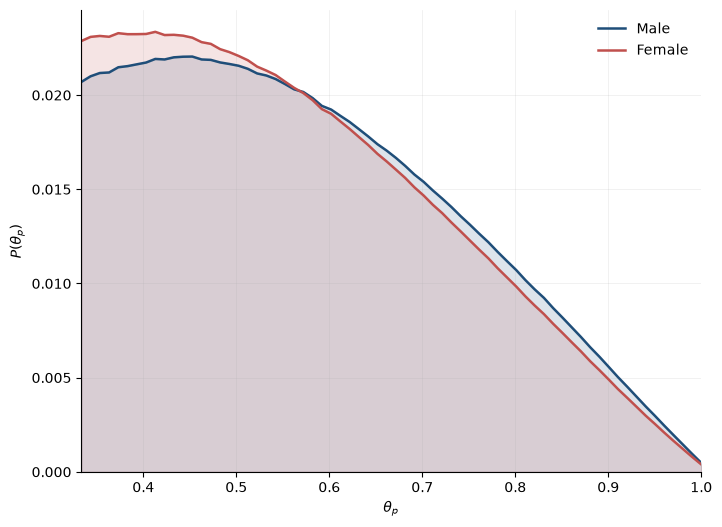

In [184]:
fig, ax = plt.subplots(figsize=(8, 6))

datasets = [
    (p_theta_p[p_theta_p['male_name'] == 1], "#1f4e79", "Male"),
    (p_theta_p[p_theta_p['male_name'] == 0], "#c0504d", "Female"),
]

for df, color, label in datasets:
    ax.plot(df["theta_p"], df["p_theta_p"], color=color, lw=1.8, label=label)
    ax.fill_between(df["theta_p"], df["p_theta_p"], color=color, alpha=0.15)

ax.set_xlabel(r"$\theta_p$")
ax.set_ylabel(r"$P(\theta_p)$")
ax.set_xlim(
    min(df["theta_p"].min() for df, _, _ in datasets),
    max(df["theta_p"].max() for df, _, _ in datasets),
)
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, lw=0.5)
ax.legend(frameon=False)

fig.savefig(f"{Path.cwd().parent}/figures/posterior_theta_p_both.png", dpi=300)
plt.show()

<h3>Distribution properties</h3>

In [192]:
for dataset, _, label in datasets:
    
    expected_value = sum(dataset["theta_p"] * dataset["p_theta_p"])
    variance = sum((dataset["theta_p"] - expected_value)**2 * dataset["p_theta_p"])
    
    print(label)
    print(f"Expected value: {round(expected_value, 6)}")
    print(f"Variance: {round(variance, 6)}")
    print("\n")

Male
Expected value: 0.578678
Variance: 0.025907


Female
Expected value: 0.568692
Variance: 0.025229




Men show a slight advantage to their female counterparts.

<h2>$P(\theta_c = \theta_{c,i} | c = c_i)$</h2>

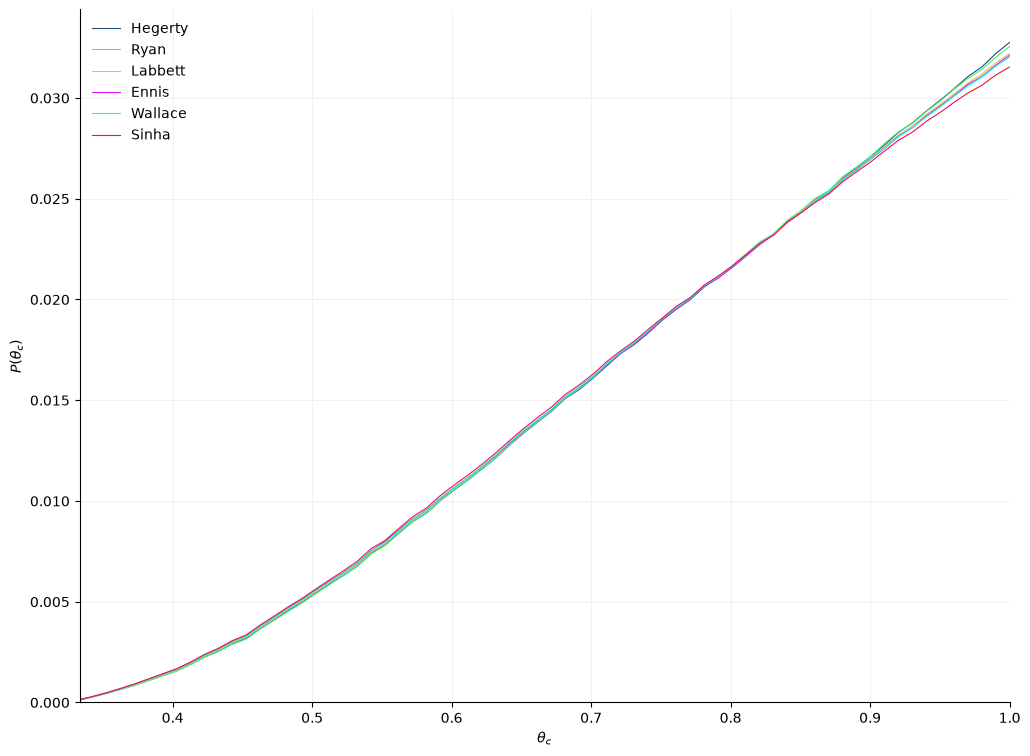

In [194]:
fig, ax = plt.subplots(figsize=(12, 9))

datasets = [
    (p_theta_c[p_theta_c['chaser_name'] == 'Anne Hegerty'], "#1f4e79", 'Hegerty'),
    (p_theta_c[p_theta_c['chaser_name'] == 'Jenny Ryan'], "#42f578", 'Ryan'),
    (p_theta_c[p_theta_c['chaser_name'] == 'Mark Labbett'], "#f5b942", 'Labbett'),
    (p_theta_c[p_theta_c['chaser_name'] == 'Darragh Ennis'], "#d916f2", 'Ennis'),
    (p_theta_c[p_theta_c['chaser_name'] == 'Shaun Wallace'], "#05fcfc", 'Wallace'),
    (p_theta_c[p_theta_c['chaser_name'] == 'Paul Sinha'], "#f50f48", 'Sinha')
]

for df, color, label in datasets:
    ax.plot(df["theta_c"], df["p_theta_c"], color=color, lw=0.8, label=label)

ax.set_xlabel(r"$\theta_c$")
ax.set_ylabel(r"$P(\theta_c)$")
ax.set_xlim(
    min(df["theta_c"].min() for df, _, _ in datasets),
    max(df["theta_c"].max() for df, _, _ in datasets),
)
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, lw=0.5)
ax.legend(frameon=False)

fig.savefig(f"{Path.cwd().parent}/figures/posterior_theta_c_both.png", dpi=400)
plt.show()

<h3>Distribution properties</h3>

In [196]:
for dataset, _, label in datasets:
    
    expected_value = sum(dataset["theta_c"] * dataset["p_theta_c"])
    variance = sum((dataset["theta_c"] - expected_value)**2 * dataset["p_theta_c"])
    
    print(label)
    print(f"Expected value: {round(expected_value, 6)}")
    print(f"Variance: {round(variance, 6)}")
    print("\n")

Hegerty
Expected value: 0.800581
Variance: 0.021713


Ryan
Expected value: 0.80067
Variance: 0.021619


Labbett
Expected value: 0.799576
Variance: 0.021766


Ennis
Expected value: 0.798922
Variance: 0.021905


Wallace
Expected value: 0.798962
Variance: 0.02185


Sinha
Expected value: 0.797688
Variance: 0.021944




The difference between two chaser with the greatest expected value of $\theta_c$ and the chaser with the lowest is incredibly small (0.002893). This vindicates the supposed lowest performing chasers. 